# 08 - Beyond Text: Diffusion and Action Outputs

## Imports

In [ ]:
import warnings
# Same known benign numpy 2.x + Apple Accelerate BLAS quirk as the other notebooks;
# spurious RuntimeWarnings on some matmuls with no actual NaN/Inf in the result.
warnings.filterwarnings('ignore', category=RuntimeWarning)

import numpy as np
import matplotlib.pyplot as plt

# Make sure we get outputs from a probabilistic model each time (for reproducibility)
np.random.seed(1515)
rng = np.random.default_rng(1515)

## What `01`-`07` Can't Do

Every output so far has been a **discrete token**. A robot's output might be a continuous action, or more often a short *sequence* of them (a trajectory), chosen in response to what the camera sees.

That sounds like a small change but it exposes a real problem. Suppose an obstacle sits directly ahead and a human driver's demonstrations go around it, sometimes on the left and sometimes on the right. Both are good answers. A model trained with a standard regression loss on those demonstrations learns to output the **average** of the two, which is a straight line through the obstacle. `perception_primer/07-multi-hypothesis-prediction.ipynb` hit the same wall for predicting *other* agents' trajectories; here it's the robot's own policy.

This notebook builds that exact failure, then two fixes that real robot-learning systems use. One generates the trajectory by **diffusion**. The other turns actions into tokens, so `04`'s generation loop applies unchanged.

## Where the Training Data Comes From

 **Imitation learning** is when we collect (observation, action) pairs from an expert, such as a human teleoperating the robot, and train a model to reproduce what the expert did. The simplest version, **behavior cloning**, is ordinary supervised learning where the label is the expert's action. `rl_primer`'s imitation learning notebook covers it properly, including why a cloned policy can drift into situations the expert never demonstrated. This notebook only needs the dataset.

Our toy expert drives a 2D path across 8 waypoints. The observation is the obstacle's lateral position `o`. The expert always clears the obstacle by going around it on one side or the other, picked at random:

In [2]:
N_WAYPOINTS = 8
x_pos = np.arange(N_WAYPOINTS)
bump = np.sin(np.pi * x_pos / (N_WAYPOINTS - 1))              # 0 at start and end, ~1 in the middle
wobble = np.sin(2 * np.pi * x_pos / (N_WAYPOINTS - 1))        # a small, demo-to-demo variation in shape
AVOID = 1.0                                                   # how far to the side the expert swings
OBSTACLE_HALF_WIDTH = 0.5                                     # obstacle occupies o +/- 0.5 at waypoints 2..5

def expert_demos(n, rng, obstacle=None):
    """n demonstrations: obstacle position o (the observation) and the expert's trajectory (the action)."""
    o = rng.uniform(-0.5, 0.5, n) if obstacle is None else np.full(n, float(obstacle))
    side = rng.choice([-1.0, 1.0], n)                         # go around on the left or the right
    traj = (o + side * AVOID)[:, None] * bump
    traj += 0.05 * rng.standard_normal((n, 1)) * wobble + 0.02 * rng.standard_normal((n, N_WAYPOINTS))
    return o, traj, side

def collides(o, traj):
    """True where any of the middle waypoints lands inside the obstacle."""
    return np.any(np.abs(traj[:, 2:6] - o[:, None]) < OBSTACLE_HALF_WIDTH, axis=1)

N_DEMOS = 4000
demo_o, demo_traj, demo_side = expert_demos(N_DEMOS, rng)
print(f"{N_DEMOS} demonstrations, each {N_WAYPOINTS} waypoints. Expert collision rate: {collides(demo_o, demo_traj).mean():.1%}")

4000 demonstrations, each 8 waypoints. Expert collision rate: 0.0%


## The Failure: a Regression Head Averages the Modes

The obvious policy model is the **Regression Head** from `deep_learning_primer/02`: obstacle position in, trajectory out, trained to minimize mean squared error. Minimizing squared error against a distribution of answers has one optimal output, the **mean** of that distribution. We can solve for it directly with least squares instead of training a network, since a linear model is already enough to find the mean:

Regression policy collision rate across test obstacle positions: 100%


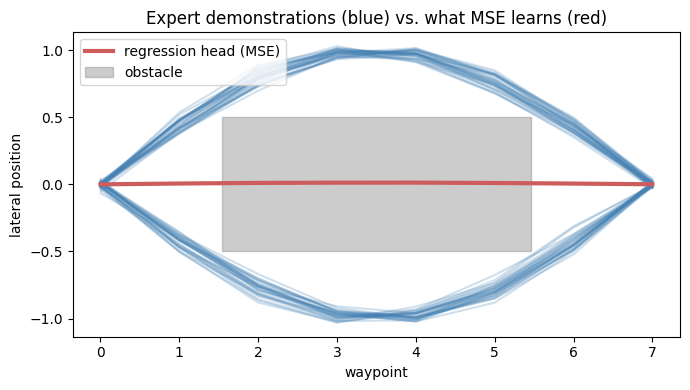

In [3]:
features = np.column_stack([demo_o, np.ones(N_DEMOS)])
regression_weights, *_ = np.linalg.lstsq(features, demo_traj, rcond=None)

def regression_policy(o):
    return np.column_stack([o, np.ones(len(o))]) @ regression_weights

test_o = np.linspace(-0.5, 0.5, 5)
reg_trajs = regression_policy(test_o)
print(f"Regression policy collision rate across test obstacle positions: {collides(test_o, reg_trajs).mean():.0%}")

# Visualize at one obstacle position: the expert's two routes vs the regression output
fig, ax = plt.subplots(figsize=(7, 4))
_, demo_view, _ = expert_demos(60, rng, obstacle=0.0)
for t in demo_view:
    ax.plot(x_pos, t, color='steelblue', alpha=0.25)
ax.plot(x_pos, regression_policy(np.array([0.0]))[0], color='indianred', lw=3, label='regression head (MSE)')
ax.axhspan(-OBSTACLE_HALF_WIDTH, OBSTACLE_HALF_WIDTH, xmin=2/7 - 0.04, xmax=5/7 + 0.04, color='gray', alpha=0.4, label='obstacle')
ax.set_title('Expert demonstrations (blue) vs. what MSE learns (red)')
ax.set_xlabel('waypoint'); ax.set_ylabel('lateral position'); ax.legend(loc='upper left')
plt.tight_layout(); plt.show()

The regression head is *optimal* by its own loss function, because it found the exact average of the demonstrations. It's also useless because its a straight line into the obstacle, 100% of the time. Nothing is wrong with the data or the training. The loss function simply has no way to say "pick one of these." It has to be asked a different question. Instead of what is the average good action, what is the distribution of good actions, and can I sample from it?

## Diffusion: Generate by Removing Noise

A **diffusion model** answers that question indirectly. Take any real trajectory and corrupt it by adding a little Gaussian noise, then a little more, over `T` steps, until nothing is left but pure noise. That **forward process** needs no learning at all, just a schedule for how much noise to add at each step. The **reverse process** is what gets trained: a network that looks at a noisy trajectory and predicts the noise that was added. Subtracting its guess gives a slightly cleaner trajectory. Repeat from pure noise `T` times and a brand-new, realistic trajectory comes out.

Each sampling run starts from a different random noise vector, and the denoiser pushes it toward whichever mode is nearest. Different starting noise, different route, both valid. Remember, we didn't specify a preference for going left or right of the object, because we currently don't have a preference. The forward process has a closed form, so any step `t` can be produced in one shot from a clean trajectory $x_0$ and fresh noise $\epsilon$:

$$x_t = \sqrt{\bar\alpha_t}\, x_0 + \sqrt{1 - \bar\alpha_t}\, \epsilon, \qquad \epsilon \sim \mathcal{N}(0, I)$$

where $\bar\alpha_t$ is the running product of $(1 - \beta_s)$ over the noise schedule $\beta$. At $t = 0$ it's almost entirely $x_0$; by $t = T$ it's almost entirely $\epsilon$.

In [4]:
T = 50
betas = np.linspace(1e-3, 0.25, T)          # how much noise each step adds
alphas = 1.0 - betas
alpha_bar = np.cumprod(alphas)              # fraction of the original signal left after each step

print(f"Signal remaining after step 1:  sqrt(alpha_bar) = {np.sqrt(alpha_bar[0]):.3f}")
print(f"Signal remaining after step {T}: sqrt(alpha_bar) = {np.sqrt(alpha_bar[-1]):.3f}   (should be near 0: almost pure noise)")

Signal remaining after step 1:  sqrt(alpha_bar) = 0.999
Signal remaining after step 50: sqrt(alpha_bar) = 0.032   (should be near 0: almost pure noise)


### The Denoiser Network

The denoiser is the same kind of network `04` trained by hand. It is a feedforward net with ReLU, backpropagated manually. Its input is the noisy trajectory (8 numbers), the obstacle position (the observation it's conditioned on), and the current step `t` (so it knows how much noise to expect). Its output is a guess at the noise, in the form of 8 numbers. The loss is plain mean squared error between its guess and the noise we actually added. That MSE target is a noise we chose, not a plan to average, which is why it doesn't hit the averaging problem above. We use an Adam optimizer in place plain gradient descent here because it converges much faster on this kind of problem (the reason why is well out of the scope of this primer).

In [5]:
def relu(z):
    return np.maximum(0, z)

def init_mlp(sizes, rng):
    return [[rng.standard_normal((n_out, n_in)) * np.sqrt(2.0 / n_in), np.zeros((n_out, 1))]
            for n_in, n_out in zip(sizes[:-1], sizes[1:])]

def mlp_forward(params, X):
    activations = [X]
    for i, (W, b) in enumerate(params):
        z = W @ activations[-1] + b
        activations.append(relu(z) if i < len(params) - 1 else z)   # last layer is linear
    return activations

def mlp_backward(params, activations, d_out):
    grads, d = [], d_out
    for i in reversed(range(len(params))):
        W, _ = params[i]
        grads.append((d @ activations[i].T, d.sum(axis=1, keepdims=True)))
        if i > 0:
            d = (W.T @ d) * (activations[i] > 0)    # ReLU derivative
    return grads[::-1]

class Adam:
    def __init__(self, params, lr=1e-3, b1=0.9, b2=0.999, eps=1e-8):
        self.lr, self.b1, self.b2, self.eps, self.step = lr, b1, b2, eps, 0
        self.m = [[np.zeros_like(p) for p in layer] for layer in params]
        self.v = [[np.zeros_like(p) for p in layer] for layer in params]

    def update(self, params, grads):
        self.step += 1
        for layer, g_layer, m_layer, v_layer in zip(params, grads, self.m, self.v):
            for k in range(2):
                m_layer[k] = self.b1 * m_layer[k] + (1 - self.b1) * g_layer[k]
                v_layer[k] = self.b2 * v_layer[k] + (1 - self.b2) * g_layer[k] ** 2
                m_hat = m_layer[k] / (1 - self.b1 ** self.step)
                v_hat = v_layer[k] / (1 - self.b2 ** self.step)
                layer[k] -= self.lr * m_hat / (np.sqrt(v_hat) + self.eps)

# input: 8 noisy waypoints + obstacle position + normalized step; output: predicted noise on the 8 waypoints
denoiser = init_mlp([N_WAYPOINTS + 2, 128, 128, N_WAYPOINTS], rng)
optimizer = Adam(denoiser, lr=1e-3)

BATCH, STEPS = 256, 8000
loss_history = []
for step in range(STEPS):
    idx = rng.integers(0, N_DEMOS, BATCH)
    x0 = demo_traj[idx].T                                   # (8, batch) clean trajectories
    o = demo_o[idx][None, :]
    t = rng.integers(0, T, BATCH)                           # a random noise level per example
    eps = rng.standard_normal((N_WAYPOINTS, BATCH))
    x_t = np.sqrt(alpha_bar[t]) * x0 + np.sqrt(1 - alpha_bar[t]) * eps       # forward process, one shot

    activations = mlp_forward(denoiser, np.vstack([x_t, o, (t / T)[None, :]]))
    predicted_eps = activations[-1]
    loss_history.append(np.mean((predicted_eps - eps) ** 2))
    d_out = 2 * (predicted_eps - eps) / predicted_eps.size
    optimizer.update(denoiser, mlp_backward(denoiser, activations, d_out))

print(f"Denoising loss: start {np.mean(loss_history[:50]):.3f} -> end {np.mean(loss_history[-200:]):.3f}")

Denoising loss: start 0.577 -> end 0.043


### Sampling: Run the Reverse Process

To generate, start from pure noise at step `T` and walk backwards. At each step, ask the denoiser for its noise guess, subtract the right amount of it, and (except at the very last step) add back a small amount of fresh noise, which keeps the process sampling from the distribution rather than collapsing to one point. This is the DDPM sampling rule from Ho et al. (2020). Every generated trajectory is conditioned on the obstacle position by passing it in as the observation.

In [6]:
def sample_trajectories(o_value, n, rng, keep_steps=()):
    x = rng.standard_normal((N_WAYPOINTS, n))               # start from pure noise
    snapshots = {T: x.copy()}
    o = np.full((1, n), o_value)
    for t in reversed(range(T)):
        eps_hat = mlp_forward(denoiser, np.vstack([x, o, np.full((1, n), t / T)]))[-1]
        mean = (x - betas[t] / np.sqrt(1 - alpha_bar[t]) * eps_hat) / np.sqrt(alphas[t])
        x = mean + (np.sqrt(betas[t]) * rng.standard_normal(x.shape) if t > 0 else 0.0)
        if t in keep_steps:
            snapshots[t] = x.copy()
    return x.T, snapshots

def evaluate(sampler, obstacle_positions, n_per=200):
    """Collision rate, and what fraction of trajectories swing to the + side of the obstacle."""
    collisions, plus_side = [], []
    for ov in obstacle_positions:
        trajs = sampler(ov, n_per)
        o_vec = np.full(n_per, ov)
        collisions.append(collides(o_vec, trajs).mean())
        plus_side.append((trajs[:, 3] > ov).mean())
    return np.mean(collisions), np.mean(plus_side)

diffusion_sampler = lambda ov, n: sample_trajectories(ov, n, rng)[0]
diff_collision, diff_plus = evaluate(diffusion_sampler, test_o)
print(f"Diffusion policy: collision rate {diff_collision:.1%}, fraction swinging to the + side {diff_plus:.1%}")
print(f"Expert demos:     collision rate {collides(demo_o, demo_traj).mean():.1%}, fraction swinging to the + side {(demo_side > 0).mean():.1%}")

Diffusion policy: collision rate 2.1%, fraction swinging to the + side 41.7%
Expert demos:     collision rate 0.0%, fraction swinging to the + side 50.7%


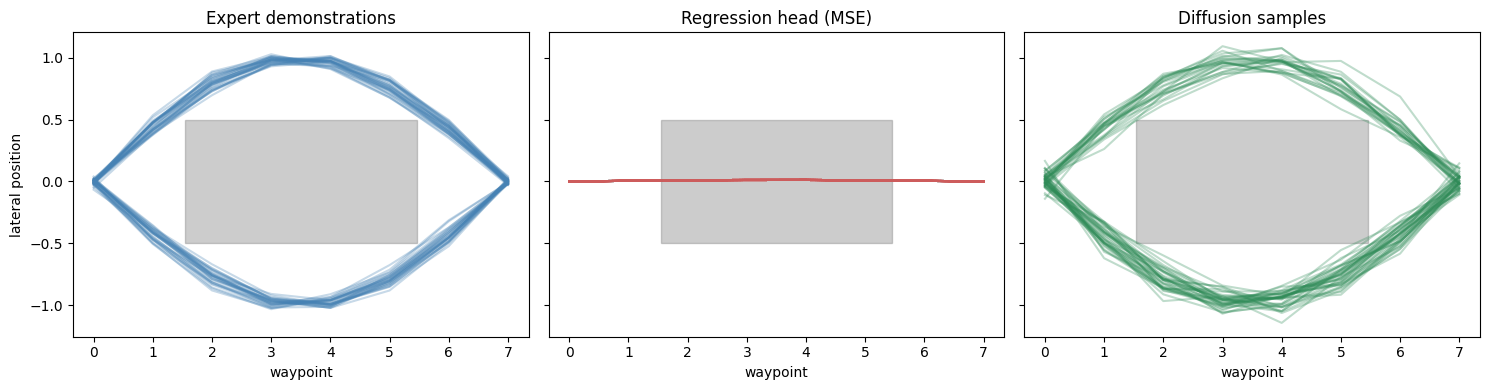

In [7]:
gen_trajs, snaps = sample_trajectories(0.0, 60, rng, keep_steps=(T // 2, T // 4, 0))

fig, axes = plt.subplots(1, 3, figsize=(15, 4), sharey=True)
panels = [("Expert demonstrations", demo_view, 'steelblue'),
          ("Regression head (MSE)", np.tile(regression_policy(np.array([0.0])), (60, 1)), 'indianred'),
          ("Diffusion samples", gen_trajs, 'seagreen')]
for ax, (title, trajs, color) in zip(axes, panels):
    for t in trajs:
        ax.plot(x_pos, t, color=color, alpha=0.3)
    ax.axhspan(-OBSTACLE_HALF_WIDTH, OBSTACLE_HALF_WIDTH, xmin=2/7 - 0.04, xmax=5/7 + 0.04, color='gray', alpha=0.4)
    ax.set_title(title); ax.set_xlabel('waypoint')
axes[0].set_ylabel('lateral position')
plt.tight_layout(); plt.show()

The green panel should look like the blue one. They're both two clusters of routes, one on each side of the obstacle. Note nothing goes through the actual obstacle. The sampling runs only ever saw random noise and an obstacle position; which side each one picked was decided by the noise it started from. The collision rate confirms the picture, and a side split that's roughly even (it wanders between about 40% and 60% from run to run, since a small network trained for a few thousand steps doesn't nail the exact 50/50 due to relatively small-ish sample size). A model that always picked one side would also avoid the obstacle, but it wouldn't be capturing the demonstrations, so the split is the number to watch alongside the collision rate.

It's worth seeing the process itself, not just its output. Here is one trajectory partway through the reverse process, starting from noise:

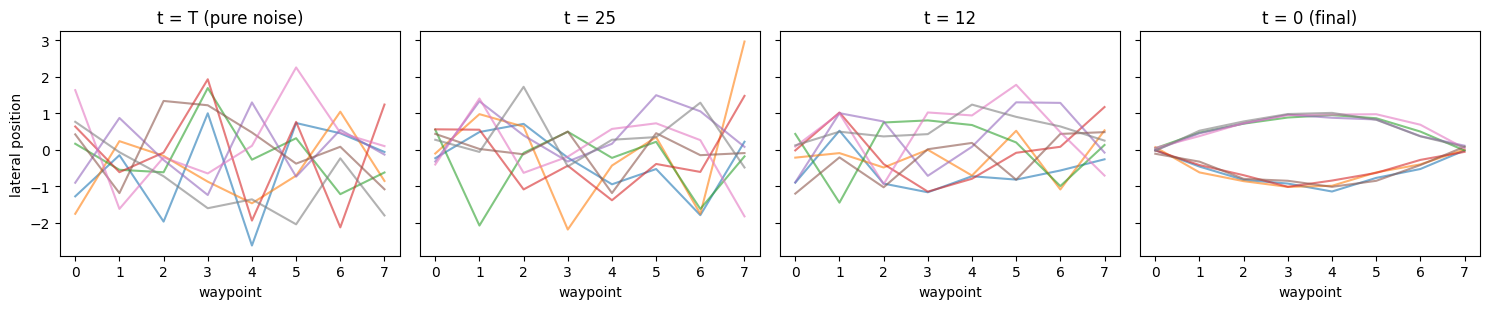

In [8]:
fig, axes = plt.subplots(1, 4, figsize=(15, 3.2), sharey=True)
for ax, (label, step) in zip(axes, [("t = T (pure noise)", T), (f"t = {T // 2}", T // 2), (f"t = {T // 4}", T // 4), ("t = 0 (final)", 0)]):
    for k in range(8):
        ax.plot(x_pos, snaps[step][:, k], alpha=0.6)
    ax.set_title(label); ax.set_xlabel('waypoint')
axes[0].set_ylabel('lateral position')
plt.tight_layout(); plt.show()

Eight different starting noise vectors turn into eight smooth trajectories that commit to one route or the other as the noise level drops. The model never explicitly chose "left" or "right". The commitment emerges partway through, which is the diffusion version of `04`'s "pick a token, feed it back in".

## Picking a Side on Purpose

Everything so far treats the fork as a feature: the model samples left or right at random because the demonstrations did. A real robot often needs the opposite. You can imagine we may want autonomous routines that only go left if one of our alliance mates decides to go right. There are four common ways to take control, and we go over the first here. 

We can condition on the direction choice. The expert's `side` was hidden from the model, which is why it had to marginalize over it. Give it as an input instead. The denoiser now learns the distribution of trajectories given the obstacle and the side, and each side on its own has only one mode. This is the same mechanism as the text prompt in image diffusion, and it's how a language instruction steers a VLA. Only the input width changes:

In [ ]:
# Same denoiser and training loop as before, with one extra input: the side the expert chose (-1 or +1).
# A separate generator keeps this section from shifting the random draws in the cells below.
cond_rng = np.random.default_rng(1516)
cond_denoiser = init_mlp([N_WAYPOINTS + 3, 128, 128, N_WAYPOINTS], cond_rng)
cond_optimizer = Adam(cond_denoiser, lr=1e-3)

cond_losses = []
for step in range(STEPS):
    idx = cond_rng.integers(0, N_DEMOS, BATCH)
    x0 = demo_traj[idx].T
    o, side = demo_o[idx][None, :], demo_side[idx][None, :]
    t = cond_rng.integers(0, T, BATCH)
    eps = cond_rng.standard_normal((N_WAYPOINTS, BATCH))
    x_t = np.sqrt(alpha_bar[t]) * x0 + np.sqrt(1 - alpha_bar[t]) * eps

    activations = mlp_forward(cond_denoiser, np.vstack([x_t, o, side, (t / T)[None, :]]))
    predicted_eps = activations[-1]
    cond_losses.append(np.mean((predicted_eps - eps) ** 2))
    d_out = 2 * (predicted_eps - eps) / predicted_eps.size
    cond_optimizer.update(cond_denoiser, mlp_backward(cond_denoiser, activations, d_out))

print(f"Conditioned denoising loss: start {np.mean(cond_losses[:50]):.3f} -> end {np.mean(cond_losses[-200:]):.3f}")

def sample_with_side(o_value, side_value, n, rng):
    x = rng.standard_normal((N_WAYPOINTS, n))
    o, side = np.full((1, n), o_value), np.full((1, n), side_value)
    for t in reversed(range(T)):
        eps_hat = mlp_forward(cond_denoiser, np.vstack([x, o, side, np.full((1, n), t / T)]))[-1]
        mean = (x - betas[t] / np.sqrt(1 - alpha_bar[t]) * eps_hat) / np.sqrt(alphas[t])
        x = mean + (np.sqrt(betas[t]) * rng.standard_normal(x.shape) if t > 0 else 0.0)
    return x.T

for side_value, name in [(-1.0, "side = -1"), (+1.0, "side = +1")]:
    sampler = lambda ov, n: sample_with_side(ov, side_value, n, cond_rng)
    collision, plus = evaluate(sampler, test_o)
    print(f"{name}: collision rate {collision:.1%}, fraction swinging to the + side {plus:.1%}")

fig, axes = plt.subplots(1, 2, figsize=(10, 4), sharey=True)
for ax, (side_value, color) in zip(axes, [(-1.0, 'darkorange'), (+1.0, 'seagreen')]):
    for tr in sample_with_side(0.0, side_value, 40, cond_rng):
        ax.plot(x_pos, tr, color=color, alpha=0.3)
    ax.axhspan(-OBSTACLE_HALF_WIDTH, OBSTACLE_HALF_WIDTH, xmin=2/7 - 0.04, xmax=5/7 + 0.04, color='gray', alpha=0.4)
    ax.set_title(f"Conditioned on side = {side_value:+.0f}"); ax.set_xlabel('waypoint')
axes[0].set_ylabel('lateral position')
plt.tight_layout(); plt.show()

Each panel holds a single cluster of routes, on the requested side and clear of the obstacle. The noise still varies the exact shape of each route, but it no longer decides which side. The model keeps its full range of behavior and you choose when to narrow it. Leave `side` out at runtime (or train with it randomly dropped, which is how classifier-free guidance works) and you get the original coin flip back.

The other three options don't need a retrained model. 

If we choose to sample many, and then rank, we would generate a batch of trajectories, scoring each one with a cost function (clearance, path length, a kee-out zone), and then run the best one. Cost comes in the form of extra samples, but it's simple and fits the companion-computer setup we talk about below. 

We could also guide the sampling, where we nudge the trajectory with the gradient of the cost at each denoising step. We could also do inpainting, where we overwrite some waypoints wiht required values (e.g., "end at this pose"). Naturally this gives us a bit more flexibility, but it requires tuning because a strong nudge can push samples off of the learned distribution. 

Finally, we could force the prefix in the same way VLAs do. Since action tokens are generated one at a time, we can set the token that picks the side and let the model complete the rest. This is the token-model version of conditioning. 

There's one failure that is important to keep an eye out for, which is that if we resample from scratch on every robot control cycle with no preference, successive plans can land on different sides. This means the robot will show some indecisiveness in front of the obstacle instead of immediately choosing a side. A usual fix is to execute a chunk of several actions before replanning (which Diffusion Policy does), or to condition on the previous plan so the choice sticks around. 

## From Image Generation to Diffusion Policy

Nothing in the loop above is specific to trajectories. **Image-generation models** (Stable Diffusion and similar) run the same forward-noise-then-learn-to-reverse recipe where $x_0$ is an image and the conditioning input is a text prompt, embedded into a vector the denoiser can use (the same kind of shared text-image space from `07`). **Diffusion Policy** (Chi et al., 2023) swaps in a different $x_0$ and different conditioning:

| | Image generation | Diffusion Policy |
|---|---|---|
| What's denoised ($x_0$) | pixels (or an image's latent vector) | a short sequence of robot actions |
| Conditioned on | text prompt embedding | camera images + robot state, through an image encoder |
| Training data | image-caption pairs | demonstrations (this notebook's setup) |

The toy denoiser here is the gist of it. Real versions use a much larger network and process 2D camera images with the vision machinery from `cv_primer` and `07`. Diffusion Policy also predicts a chunk of several future actions at once rather than one action at a time, which keeps the robot's motion smooth.

## The Other Route: Make Actions Tokens

Vision-language-action (VLA) models (RT-2, OpenVLA, and similar) take a different approach, closer to everything in `01`-`07`. They start with exactly the multimodal Transformer from `07`, images and a text instruction in, and make the robot's output just more tokens. Divide each action dimension's range into bins, give each bin an ID, and the continuous action `0.37` becomes an integer token. After that the model is `04`'s next-token predictor. It is the same Classification Head over a vocabulary, same autoregressive generation loop, but with sampling instead of averaging.

Binning costs precision, so the first thing to check is how much. Quantizing our expert's waypoints at different bin counts:

In [9]:
LOW, HIGH = -2.0, 2.0

def tokenize(y, n_bins):
    return np.clip(np.floor((y - LOW) / (HIGH - LOW) * n_bins), 0, n_bins - 1).astype(int)

def detokenize(tokens, n_bins):
    bin_width = (HIGH - LOW) / n_bins
    return LOW + (tokens + 0.5) * bin_width              # the center of each bin

for n_bins in [4, 8, 16, 64, 256]:
    reconstructed = detokenize(tokenize(demo_traj, n_bins), n_bins)
    print(f"{n_bins:4d} bins: mean absolute error {np.abs(reconstructed - demo_traj).mean():.4f}")

   4 bins: mean absolute error 0.2805
   8 bins: mean absolute error 0.1575
  16 bins: mean absolute error 0.0736
  64 bins: mean absolute error 0.0161
 256 bins: mean absolute error 0.0039


Error falls roughly in proportion to 1 / (number of bins), so 256 bins (what RT-2 and OpenVLA use per action dimension) makes the rounding negligible, at the cost of a bigger vocabulary and a longer sequence for a robot with many joints. For this demo, 16 bins (width 0.25) keeps the network small enough to train in seconds while still being granular enough to tell routes apart.

Now train the token predictor. It's `04`'s setup with different inputs. The context is the obstacle position (also binned, into 8 tokens), the previous two action tokens, and the position in the trajectory. The target is the next action token. Each is one-hot encoded and concatenated, exactly as in `04`'s word predictor.

In [10]:
N_BINS = 16
N_O_BINS = 8
PAD = N_BINS                               # a padding token for "before the trajectory started"

def one_hot(ids, size):
    out = np.zeros((size, len(ids)))
    out[ids, np.arange(len(ids))] = 1.0
    return out

def o_tokens(o):
    return np.clip(np.floor((o + 0.5) * N_O_BINS), 0, N_O_BINS - 1).astype(int)

def build_inputs(o_tok, prev1, prev2, pos):
    return np.vstack([one_hot(o_tok, N_O_BINS), one_hot(prev1, N_BINS + 1),
                      one_hot(prev2, N_BINS + 1), one_hot(pos, N_WAYPOINTS)])

action_tokens = tokenize(demo_traj, N_BINS)                      # (n_demos, 8)
rows_o, rows_prev1, rows_prev2, rows_pos, rows_target = [], [], [], [], []
for pos in range(N_WAYPOINTS):
    rows_o.append(o_tokens(demo_o))
    rows_prev1.append(action_tokens[:, pos - 1] if pos >= 1 else np.full(N_DEMOS, PAD))
    rows_prev2.append(action_tokens[:, pos - 2] if pos >= 2 else np.full(N_DEMOS, PAD))
    rows_pos.append(np.full(N_DEMOS, pos))
    rows_target.append(action_tokens[:, pos])
X_tok = build_inputs(*(np.concatenate(r) for r in (rows_o, rows_prev1, rows_prev2, rows_pos)))
Y_tok = one_hot(np.concatenate(rows_target), N_BINS)
n_tok_examples = X_tok.shape[1]
print(f"Token-prediction training examples: {n_tok_examples}, input dim: {X_tok.shape[0]}, vocabulary: {N_BINS} action tokens")

token_net = init_mlp([X_tok.shape[0], 64, N_BINS], rng)
token_opt = Adam(token_net, lr=3e-3)

def softmax(z):
    e = np.exp(z - z.max(axis=0, keepdims=True))
    return e / e.sum(axis=0, keepdims=True)

for epoch in range(1500):
    activations = mlp_forward(token_net, X_tok)
    probs = softmax(activations[-1])
    token_opt.update(token_net, mlp_backward(token_net, activations, (probs - Y_tok) / n_tok_examples))   # same cross-entropy gradient as 04

accuracy = np.mean(np.argmax(probs, axis=0) == np.argmax(Y_tok, axis=0))
print(f"Token-prediction accuracy: {accuracy:.1%}")

Token-prediction training examples: 32000, input dim: 50, vocabulary: 16 action tokens


Token-prediction accuracy: 74.0%


Accuracy won't reach 100%, and shouldn't. The first step to the side is a genuine coin flip (left or right) and the demonstrations' small shape variation adds more uncertainty. A model that knew the answer would be memorizing noise. What it should learn is the *distribution*. Here, it is roughly 50/50 between the two routes at that fork, near-certain everywhere else. Now generate with `04`'s loop: predict a distribution, sample from it, feed the sampled token back in.

In [11]:
def sample_token_trajectories(o_value, n, rng):
    o_tok = np.full(n, o_tokens(np.array([o_value]))[0])
    generated = np.zeros((n, N_WAYPOINTS), dtype=int)
    for pos in range(N_WAYPOINTS):
        prev1 = generated[:, pos - 1] if pos >= 1 else np.full(n, PAD)
        prev2 = generated[:, pos - 2] if pos >= 2 else np.full(n, PAD)
        probs = softmax(mlp_forward(token_net, build_inputs(o_tok, prev1, prev2, np.full(n, pos)))[-1])
        u = rng.random(n)
        generated[:, pos] = np.minimum((probs.cumsum(axis=0) < u).sum(axis=0), N_BINS - 1)   # sample from each column
    return detokenize(generated, N_BINS)

token_collision, token_plus = evaluate(lambda ov, n: sample_token_trajectories(ov, n, rng), test_o)
print(f"Token policy:     collision rate {token_collision:.1%}, fraction swinging to the + side {token_plus:.1%}")

Token policy:     collision rate 0.6%, fraction swinging to the + side 53.0%


In [12]:
reg_collision = collides(test_o, reg_trajs).mean()
print(f"{'Method':<24}{'collision rate':>16}{'+ side fraction':>18}")
for name, c, p in [("Regression head (MSE)", reg_collision, None),
                   ("Diffusion policy", diff_collision, diff_plus),
                   ("Action tokens (VLA-style)", token_collision, token_plus)]:
    print(f"{name:<24}{c:>16.1%}{('n/a' if p is None else format(p, '.1%')):>18}")

Method                    collision rate   + side fraction
Regression head (MSE)             100.0%               n/a
Diffusion policy                    2.1%             41.7%
Action tokens (VLA-style)            0.6%             53.0%


Both approaches avoid the obstacle and keep both routes. Regression doesn't, because it can only return one answer per observation. The differences between the two real approaches are about cost and reach, not whether they can represent a fork.

Action tokens reuse the entire language-model stack, which is why VLAs can inherit understanding of instructions. The cost is quantization and a long, serial output (one token per action dimension per time step). 

Diffusion works natively in continuous space and produces a whole smooth trajectory at once, but its sampling loop is `T` forward passes of the denoiser per action, and it can't inherit a language model. Some current VLAs like π0 actually combine the two, using a pretrained vision-language Transformer for understanding, with a diffusion-style/flow-matching action head for the output.

## Real World Systems

This notebook's pieces map directly onto real systems. 

Diffusion Policy (Chie et al., 2023) is the denoising loop above, conditioned on camera images, producing action chunks. This is widely used for learning manipulation skills for teleoperated demos. 

RT-2 (Brohan et al., 2023) and OpenVLA (Kim et al., 2024) cover the action-token approach built on top of pretrained vision-language models. 

π0 (Black et al., 2024) is a vision-language Transformer plus a flow-matching action head. This is closely related to diffusion. 

#### Limitations 

Any of the above methodologies come with some real limitations. 

The first is data, since all of them learn from demonstrations. The quality and coverage of those demos decide the ceiling. A policy is only as good as its expert, and it can fail on edge cases never covered. This is the distribution-shift the imitation learning notebook in `rl_primer` will cover. 

The second is edge computing, because diffusion needs `T` network evaluations per action (although real systems can cut this to 10-20 with faster samplers), and VLAs are multi-billion parameter Transformers. Therefore, none of these are running on a roboRIO or SystemCore. We have to therefore run inference on a more capable companion computer or a compressed model. 

Finally, there are no guarantees of the actions, because the actions generated are plausible, not verified. There must be a verification layer before it reaches a motor. 

## Try It Yourself

Two experiments, using the objects defined above:

1. **How many denoising steps does diffusion actually need?** Retrain the denoiser with `T = 5`, then `T = 10` (re-run the schedule cell and the training loop), and compare the collision rate and + side fraction to `T = 50`. Before you run it, guess: does fewer steps degrade the *quality* of each trajectory, the *diversity* of routes, or both? Write one sentence on what you actually find.
2. **How coarse can action tokens get?** Re-run the token pipeline with `N_BINS = 4`, `8`, and `32` (the tokenize, train, and sample cells). At what bin count does the token policy's collision rate start to climb, and how does that line up with the quantization-error table above?

In [13]:
# TODO: 1. retrain the diffusion denoiser with T = 5 and T = 10, then compare evaluate(...)
#          results (collision rate and + side fraction) against T = 50
#       2. rerun the action-token pipeline with N_BINS = 4, 8, and 32 and compare collision
#          rate against the quantization-error table

## Resources

- Ho, J., Jain, A., & Abbeel, P. (2020). "Denoising Diffusion Probabilistic Models." *NeurIPS 2020*. The paper that introduced the forward process and the sampling rule implemented above (paper).
- Chi, C. et al. (2023). "Diffusion Policy: Visuomotor Policy Learning via Action Diffusion." *RSS 2023*. The robot-learning version of this notebook's diffusion section, conditioned on camera images (paper).
- Brohan, A. et al. (2023). "RT-2: Vision-Language-Action Models Transfer Web Knowledge to Robotic Control." The action-tokenization approach built on a pretrained vision-language model (paper).
- Kim, M. J. et al. (2024). "OpenVLA: An Open-Source Vision-Language-Action Model." An open implementation of the same idea you can actually read and run (paper).
- Black, K. et al. (2024). "π0: A Vision-Language-Action Flow Model for General Robot Control." The hybrid of a vision-language Transformer with a diffusion-style action head (paper).
- [Lilian Weng: What are Diffusion Models?](https://lilianweng.github.io/posts/2021-07-11-diffusion-models/) - a thorough written walkthrough of the math behind the forward and reverse processes (instructional).